# DATA 620 – Project 2: Bipartite Network Analysis of MovieLens Ratings

## Introduction

For this project, I will analyze the MovieLens 100K dataset, which contains 100,000 movie ratings from 943 users across 1,682 movies.

The goal is to examine relationships between two distinct groups: users and movies. This dataset is appropriate for bipartite network analysis because connections exist between users and movies rather than within either group.

Each connection represents a user rating a particular movie. I will use Python and NetworkX to construct the network, analyze the characteristics of both groups, and reduce the network using an island-style method.

The main objective is to identify meaningful patterns in user activity and movie popularity that may be difficult to observe in the original network.

## 1. Loading and Exploring the Dataset

Before constructing the network, I will load the MovieLens dataset and examine its structure. This step will help verify the number of users, movies, and ratings and confirm that the dataset meets the requirements for a bipartite network.

Each row represents a user rating a movie, with a rating value between 1 and 5.

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request
import zipfile
from pathlib import Path

# Download the MovieLens 100K dataset
url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

zip_path = Path("ml-100k.zip")

# Extract the dataset
if not Path("ml-100k/u.data").exists():
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(".")

# Load ratings
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print("FIRST FIVE ROWS")
display(ratings.head())

print("\nDATASET SUMMARY")
print("Total ratings:", len(ratings))
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies:", ratings["movie_id"].nunique())

print("\nRATING DISTRIBUTION")
display(ratings["rating"].value_counts().sort_index())

FIRST FIVE ROWS


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596



DATASET SUMMARY
Total ratings: 100000
Unique users: 943
Unique movies: 1682

RATING DISTRIBUTION


rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


### Initial Observations

The MovieLens 100K dataset contains 100,000 ratings from 943 users across 1,682 movies. Each observation represents a user rating a particular movie on a scale from 1 to 5.

The rating distribution shows that ratings of 4 were the most common (34,174), followed by ratings of 3 (27,145) and 5 (21,201). This suggests that users generally gave more positive than negative ratings.

The dataset is suitable for bipartite network analysis because it contains relationships between two distinct groups: users and movies. The rating values can also be used as edge attributes when examining user preferences.

In the next section, I will construct the network and verify that connections only exist between users and movies.

## 2. Constructing the Bipartite Network

The next step is to transform the ratings dataset into a network using NetworkX.

In this network, there are two types of nodes:

- **Users:** Individuals who submitted movie ratings.
- **Movies:** Movies that received ratings.

An edge connects a user to a movie when that user has rated it. Each edge also contains a rating value between 1 and 5.

It is important to distinguish between the existence of a connection and its rating value. A rating of 1 still represents a connection, even though it indicates a negative opinion of the movie.

I will verify that the resulting graph is bipartite and examine its basic characteristics, including the number of nodes, edges, and network density.

In [2]:
from networkx.algorithms import bipartite

# Create an undirected bipartite network
G = nx.Graph()

# Create unique node identifiers to distinguish users from movies
user_nodes = ["user_" + str(uid) for uid in ratings["user_id"].unique()]
movie_nodes = ["movie_" + str(mid) for mid in ratings["movie_id"].unique()]

# Add users and movies as separate groups
G.add_nodes_from(user_nodes, bipartite=0)
G.add_nodes_from(movie_nodes, bipartite=1)

# Add an edge for each movie rating
for row in ratings.itertuples(index=False):
    G.add_edge(
        f"user_{row.user_id}",
        f"movie_{row.movie_id}",
        rating=row.rating
    )

# Calculate network characteristics
num_users = len(user_nodes)
num_movies = len(movie_nodes)
num_edges = G.number_of_edges()
possible_edges = num_users * num_movies

print("BIPARTITE NETWORK SUMMARY")
print("Total nodes:", G.number_of_nodes())
print("User nodes:", num_users)
print("Movie nodes:", num_movies)
print("Total edges:", num_edges)

print("\nNETWORK VALIDATION")
print("Is bipartite:", bipartite.is_bipartite(G))
print("Network density:", round(num_edges / possible_edges, 4))
print("Connected components:", nx.number_connected_components(G))

BIPARTITE NETWORK SUMMARY
Total nodes: 2625
User nodes: 943
Movie nodes: 1682
Total edges: 100000

NETWORK VALIDATION
Is bipartite: True
Network density: 0.063
Connected components: 1


### Network Construction Results

The constructed network contains 2,625 nodes and 100,000 edges, representing 943 users and 1,682 movies.

NetworkX confirmed that the graph is bipartite, meaning all connections exist between users and movies rather than within the same group.

The network density is approximately 0.063, indicating that only 6.3% of all possible user-movie relationships exist. This suggests that individual users have rated a relatively small portion of the available movies.

Interestingly, the network contains only one connected component. This means that all users and movies are connected either directly or indirectly through shared rating activity.

Although the network is relatively sparse, it is still fully connected. This makes it an interesting dataset for exploring how user activity and movie popularity contribute to the overall network structure.

## 3. Analyzing Users and Movies

Before reducing the network, I will examine the characteristics of the two distinct groups.

For users, degree represents the number of movies they have rated. Users with higher degrees are more active participants in the dataset.

For movies, degree represents the number of users who rated them. Movies with higher degrees have received more attention from users.

I will compare the distributions of connections across both groups and identify the most active users and most frequently rated movies.

This analysis will establish a baseline for comparing the original network with the reduced network later in the project.

USER ACTIVITY SUMMARY


count    943.00
mean     106.04
std      100.93
min       20.00
25%       33.00
50%       65.00
75%      148.00
max      737.00
Name: Movies_Rated, dtype: float64


MOVIE POPULARITY SUMMARY


count    1682.00
mean       59.45
std        80.38
min         1.00
25%         6.00
50%        27.00
75%        80.00
max       583.00
Name: Number_of_Ratings, dtype: float64


TOP 10 MOST ACTIVE USERS


,User,Movies_Rated
402,user_405,737
650,user_655,685
58,user_13,636
442,user_450,540
37,user_276,518
409,user_416,493
534,user_537,490
15,user_303,484
19,user_234,480
387,user_393,448



TOP 10 MOST FREQUENTLY RATED MOVIES


,title,Number_of_Ratings
357,Star Wars (1977),583
157,Contact (1997),509
49,Fargo (1996),508
52,Return of the Jedi (1983),507
95,Liar Liar (1997),485
289,"English Patient, The (1996)",481
60,Scream (1996),478
24,Toy Story (1995),452
652,Air Force One (1997),431
403,Independence Day (ID4) (1996),429


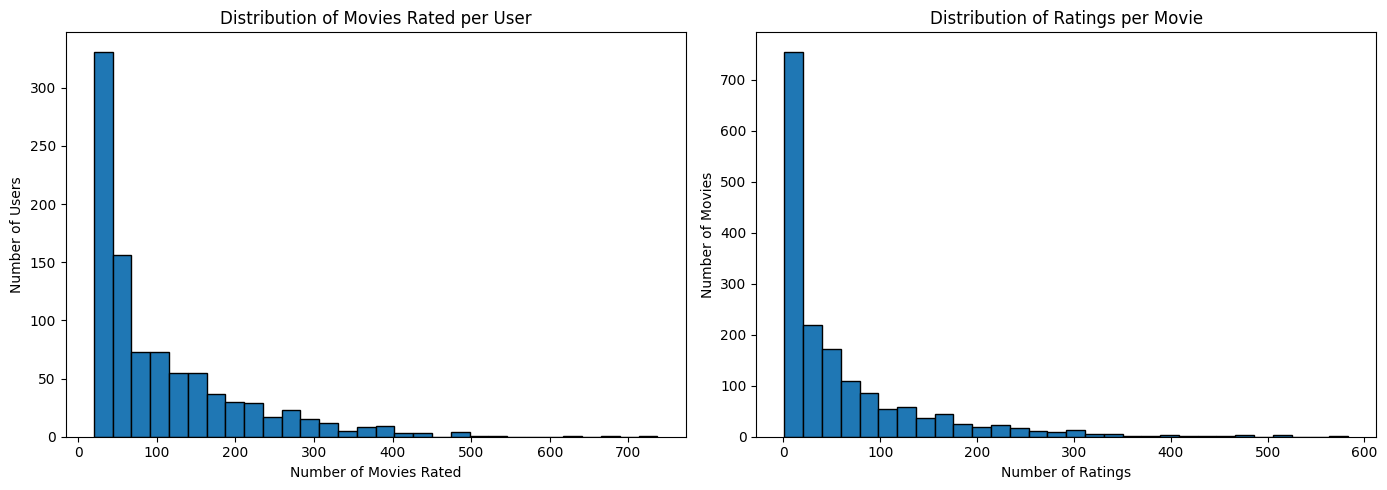

In [3]:
# Load movie information
movie_columns = [
    "movie_id", "title", "release_date", "video_release_date",
    "imdb_url", "unknown", "Action", "Adventure", "Animation",
    "Children", "Comedy", "Crime", "Documentary", "Drama",
    "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery",
    "Romance", "Sci-Fi", "Thriller", "War", "Western"
]

movies = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    names=movie_columns
)

# Calculate the number of movies rated by each user
user_degrees = pd.DataFrame({
    "User": user_nodes,
    "Movies_Rated": [G.degree(user) for user in user_nodes]
})

# Calculate the number of ratings received by each movie
movie_degrees = pd.DataFrame({
    "movie_id": [int(movie.split("_")[1]) for movie in movie_nodes],
    "Number_of_Ratings": [G.degree(movie) for movie in movie_nodes]
})

# Add movie titles
movie_degrees = movie_degrees.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

# Display summary statistics
print("USER ACTIVITY SUMMARY")
display(user_degrees["Movies_Rated"].describe().round(2))

print("\nMOVIE POPULARITY SUMMARY")
display(movie_degrees["Number_of_Ratings"].describe().round(2))

# Display the most active users
print("\nTOP 10 MOST ACTIVE USERS")
display(
    user_degrees.sort_values(
        "Movies_Rated", ascending=False
    ).head(10)
)

# Display the most frequently rated movies
print("\nTOP 10 MOST FREQUENTLY RATED MOVIES")
display(
    movie_degrees.sort_values(
        "Number_of_Ratings", ascending=False
    )[["title", "Number_of_Ratings"]].head(10)
)

# Visualize the degree distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(user_degrees["Movies_Rated"], bins=30, edgecolor="black")
axes[0].set_title("Distribution of Movies Rated per User")
axes[0].set_xlabel("Number of Movies Rated")
axes[0].set_ylabel("Number of Users")

axes[1].hist(movie_degrees["Number_of_Ratings"], bins=30, edgecolor="black")
axes[1].set_title("Distribution of Ratings per Movie")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

### Interpretation of User and Movie Activity

The results show that both user activity and movie popularity are unevenly distributed.

**User Activity**

Users rated an average of 106 movies, but the median was only 65. This difference suggests that a relatively small number of highly active users are increasing the average.

For example, User 405 rated 737 movies, while the minimum was only 20. The histogram also shows that most users rated relatively few movies, with a smaller number of users contributing significantly more ratings.

**Movie Popularity**

A similar pattern appears among movies. The average movie received approximately 59 ratings, while the median received only 27.

Star Wars (1977) was the most frequently rated movie with 583 ratings, followed by Contact (1997) with 509 and Fargo (1996) with 508.

The movie histogram is strongly right-skewed, indicating that most movies received relatively few ratings while a smaller number attracted substantially more attention.

**What This Means for Our Network**

These findings suggest that the network contains significant differences in connectivity across both groups.

Highly active users and frequently rated movies may play important roles in connecting different parts of the network. However, a high number of ratings does not necessarily indicate positive opinions.

This analysis provides a baseline for evaluating how the network changes when we apply a reduction method.

## 4. Network Reduction Using an Island-Style Method

The original bipartite network contains 2,625 nodes and 100,000 edges. Visualizing every connection would make it difficult to identify meaningful patterns.

To reduce the network, I will apply an island-style approach that retains stronger connections while removing weaker ones.

In the MovieLens dataset, each edge contains a rating between 1 and 5. I will use these ratings as weights, allowing me to focus on users' stronger movie preferences.

The reduction process will involve testing different rating thresholds and examining how the number of nodes, edges, and connected components changes.

This approach preserves the original bipartite structure because connections will still exist only between users and movies.

One important limitation is that a higher rating represents a stronger preference for a movie, rather than a stronger interpersonal relationship. Therefore, the reduced network will represent positive movie preferences rather than overall movie-rating activity.

In [4]:
# Test different rating thresholds for network reduction

threshold_results = []

for threshold in [1, 2, 3, 4, 5]:

    # Keep only ratings at or above the threshold
    selected_edges = [
        (u, v, data)
        for u, v, data in G.edges(data=True)
        if data["rating"] >= threshold
    ]

    # Construct the reduced network
    reduced = nx.Graph()
    reduced.add_edges_from(selected_edges)

    # Count the remaining users and movies
    remaining_users = sum(
        1 for node in reduced.nodes()
        if node.startswith("user_")
    )

    remaining_movies = sum(
        1 for node in reduced.nodes()
        if node.startswith("movie_")
    )

    threshold_results.append({
        "Minimum_Rating": threshold,
        "Users": remaining_users,
        "Movies": remaining_movies,
        "Total_Nodes": reduced.number_of_nodes(),
        "Edges": reduced.number_of_edges(),
        "Components": nx.number_connected_components(reduced)
    })

threshold_df = pd.DataFrame(threshold_results)

print("NETWORK REDUCTION BY RATING THRESHOLD")
display(threshold_df)

NETWORK REDUCTION BY RATING THRESHOLD


,Minimum_Rating,Users,Movies,Total_Nodes,Edges,Components
0,1,943,1682,2625,100000,1
1,2,943,1612,2555,93890,1
2,3,943,1574,2517,82520,1
3,4,942,1447,2389,55375,1
4,5,928,1172,2100,21201,1


### Interpretation of Network Reduction Results

The results show that increasing the minimum rating threshold significantly reduces the size of the network.

The original network contained 2,625 nodes and 100,000 edges. When the minimum rating was increased to 4, the network decreased to 2,389 nodes and 55,375 edges. At a threshold of 5, the network contained 2,100 nodes and 21,201 edges, representing a reduction of approximately 79% of the original connections.

Interestingly, the network remained a single connected component at every threshold. This suggests that even when considering only highly rated movies, users and movies remain indirectly connected through shared rating activity.

Although filtering by rating strength substantially reduced the number of edges, the remaining network is still too large to visualize effectively.

For the next stage, I will apply an additional reduction method by selecting the most connected users and movies within the 5-star network. This will allow me to create a smaller, more interpretable network while preserving the bipartite structure.

One limitation is that using ratings as edge weights focuses on positive movie preferences rather than the overall frequency of interactions.

## 5. Creating a Reduced Bipartite Network

The previous analysis showed that filtering the network to only 5-star ratings reduced the number of edges significantly. However, the remaining network still contains 2,100 nodes and 21,201 edges, making it difficult to visualize and interpret.

To further reduce the network, I will select the 20 users who gave the most 5-star ratings and the 20 movies that received the most 5-star ratings.

I chose this approach because it allows me to focus on highly active users and popular movies while keeping the network small enough to visualize. By retaining only the existing connections between these selected nodes, the network will remain bipartite.

This is an additional degree-based filtering step following the rating threshold, rather than a strict implementation of the island method.

The goal is to examine how these highly connected users and movies relate to one another and determine what patterns emerge from the reduced network.

In [5]:
# Create a network containing only 5-star ratings
G5 = nx.Graph()

G5.add_edges_from(
    (u, v, data)
    for u, v, data in G.edges(data=True)
    if data["rating"] == 5
)

# Separate the two groups
users_5 = [n for n in G5.nodes() if n.startswith("user_")]
movies_5 = [n for n in G5.nodes() if n.startswith("movie_")]

# Select the 20 most connected users and movies
top_users = sorted(
    users_5, key=lambda n: G5.degree(n), reverse=True
)[:20]

top_movies = sorted(
    movies_5, key=lambda n: G5.degree(n), reverse=True
)[:20]

# Create the reduced network
G_small = G5.subgraph(top_users + top_movies).copy()

# Display network characteristics
print("REDUCED BIPARTITE NETWORK")
print("Total nodes:", G_small.number_of_nodes())
print("Users:", len(top_users))
print("Movies:", len(top_movies))
print("Edges:", G_small.number_of_edges())
print("Is bipartite:", bipartite.is_bipartite(G_small))
print("Connected components:", nx.number_connected_components(G_small))

# Show the most connected users in the reduced network
print("\nTOP USERS IN REDUCED NETWORK")

for user in sorted(
    top_users, key=lambda n: G_small.degree(n), reverse=True
)[:10]:
    print(user, "-", G_small.degree(user), "connections")

# Show the most connected movies in the reduced network
print("\nTOP MOVIES IN REDUCED NETWORK")

for movie in sorted(
    top_movies, key=lambda n: G_small.degree(n), reverse=True
)[:10]:
    movie_id = int(movie.split("_")[1])
    title = movies.loc[
        movies["movie_id"] == movie_id, "title"
    ].iloc[0]

    print(title, "-", G_small.degree(movie), "connections")

REDUCED BIPARTITE NETWORK
Total nodes: 40
Users: 20
Movies: 20
Edges: 234
Is bipartite: True
Connected components: 1

TOP USERS IN REDUCED NETWORK
user_416 - 19 connections
user_592 - 18 connections
user_59 - 16 connections
user_474 - 16 connections
user_457 - 15 connections
user_747 - 14 connections
user_472 - 14 connections
user_151 - 13 connections
user_7 - 12 connections
user_532 - 12 connections

TOP MOVIES IN REDUCED NETWORK
Star Wars (1977) - 15 connections
Raiders of the Lost Ark (1981) - 15 connections
Schindler's List (1993) - 15 connections
Usual Suspects, The (1995) - 14 connections
Fargo (1996) - 13 connections
Godfather, The (1972) - 13 connections
Pulp Fiction (1994) - 13 connections
Silence of the Lambs, The (1991) - 13 connections
Shawshank Redemption, The (1994) - 13 connections
Casablanca (1942) - 13 connections


### Interpretation of the Reduced Network

The reduced network contains 40 nodes, consisting of 20 users and 20 movies, with 234 connections between them. Compared to the original network of 2,625 nodes and 100,000 edges, this represents a substantial reduction in size.

The network is still bipartite, meaning that connections only exist between users and movies, not within either group. It also remains a single connected component, suggesting that the selected users and movies are connected through shared positive movie preferences.

Among the users, user_416 has the most connections, giving 5-star ratings to 19 of the 20 selected movies. User_592 follows with 18 connections. This suggests that these users share strong preferences for many of the highly rated movies in our sample.

Among the movies, Star Wars (1977), Raiders of the Lost Ark (1981), and Schindler's List (1993) each received 5-star ratings from 15 of the 20 selected users. Other movies, including The Godfather, Pulp Fiction, and The Shawshank Redemption, also have a high number of connections.

These findings suggest that the selected users share an interest in several widely appreciated movies, particularly well-known classics and popular films.

However, because the network focuses on the most connected users and movies, these results should not be generalized to all users in the original dataset.

The next step is to visualize the reduced network to better understand how the two groups are connected.

## 6. Visualizing the Reduced Bipartite Network

To better understand the relationships between users and movies, I will visualize the reduced network using a bipartite layout.

Users will appear on the left side of the graph, while movies will appear on the right. Connections represent 5-star ratings given by users to specific movies.

This layout makes it easier to identify highly connected users, frequently rated movies, and patterns of shared preferences.

Since the network contains only 40 nodes, it should be considerably easier to interpret than the original network.

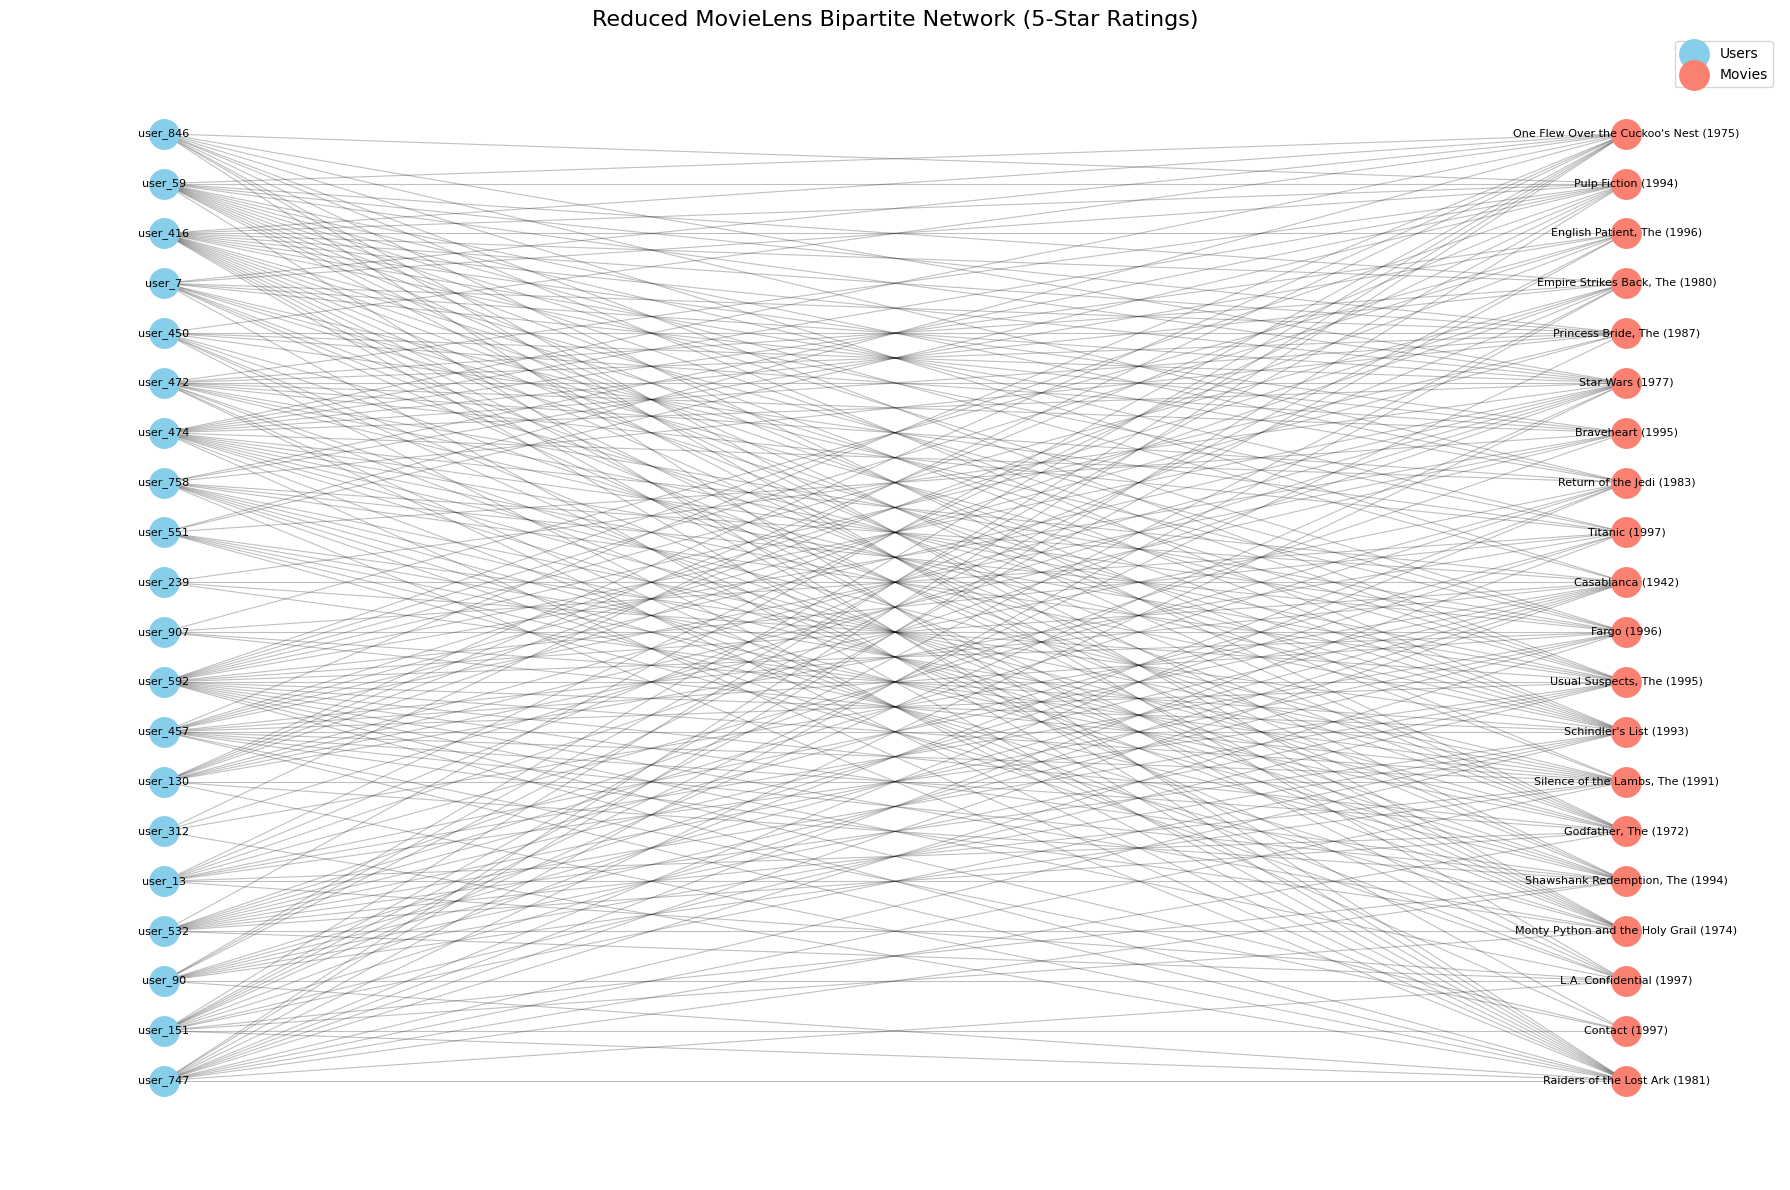

In [6]:
# Create a bipartite layout for the reduced network
pos = nx.bipartite_layout(G_small, top_users, align="vertical")

plt.figure(figsize=(18, 12))

# Draw users
nx.draw_networkx_nodes(
    G_small,
    pos,
    nodelist=top_users,
    node_color="skyblue",
    node_size=450,
    label="Users"
)

# Draw movies
nx.draw_networkx_nodes(
    G_small,
    pos,
    nodelist=top_movies,
    node_color="salmon",
    node_size=450,
    label="Movies"
)

# Draw connections
nx.draw_networkx_edges(
    G_small,
    pos,
    alpha=0.25,
    width=0.8
)

# Replace movie IDs with movie titles
labels = {}

for node in top_users:
    labels[node] = node

for node in top_movies:
    movie_id = int(node.split("_")[1])
    labels[node] = movies.loc[
        movies["movie_id"] == movie_id, "title"
    ].iloc[0]

nx.draw_networkx_labels(
    G_small,
    pos,
    labels=labels,
    font_size=8
)

plt.title("Reduced MovieLens Bipartite Network (5-Star Ratings)", fontsize=16)
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

### Interpretation of the Reduced Bipartite Network Visualization

The visualization shows the relationships between 20 users and 20 movies based on 5-star ratings. Users are represented by blue nodes on the left, while movies are represented by red nodes on the right.

The network contains 234 connections out of 400 possible user-to-movie connections, indicating that approximately 58.5% of the possible connections are present. This suggests a relatively high level of shared positive movie preferences among the selected users.

The graph also confirms the bipartite structure, since all connections occur between users and movies rather than within either group.

Several users are connected to a large number of movies, suggesting that they have broad preferences across the selected films. Similarly, movies such as Star Wars, Raiders of the Lost Ark, and Schindler's List received 5-star ratings from many of the selected users.

However, the large number of overlapping edges makes it difficult to identify individual relationships or smaller groups visually. This is partly because the network was constructed using the most connected users and movies.

Overall, the visualization suggests that highly active users share positive preferences for many of the same popular movies. However, the findings represent a selected subset of the MovieLens dataset rather than the entire network.

## 7. Analyzing the Two Groups in the Reduced Network

The reduced bipartite network consists of two distinct groups: users and movies. While the previous visualization showed how these groups are connected, it did not fully explain the characteristics of each group.

To better understand the movie group, I will examine the genres represented among the 20 selected movies. This can help identify whether certain genres are more common among movies receiving a high number of 5-star ratings.

For the user group, I will examine how many of the selected movies each user rated 5 stars and explore whether users share similar preferences.

This analysis will help determine what can be inferred about both groups beyond their overall connectivity.

Because the network was reduced by selecting highly connected users and movies, the findings will describe this specific subset rather than the entire MovieLens dataset.

GENRE DISTRIBUTION AMONG THE 20 SELECTED MOVIES


,Number_of_Movies
Drama,13
Action,8
War,7
Romance,7
Adventure,5
Crime,5
Thriller,4
Sci-Fi,4
Comedy,2
Mystery,1


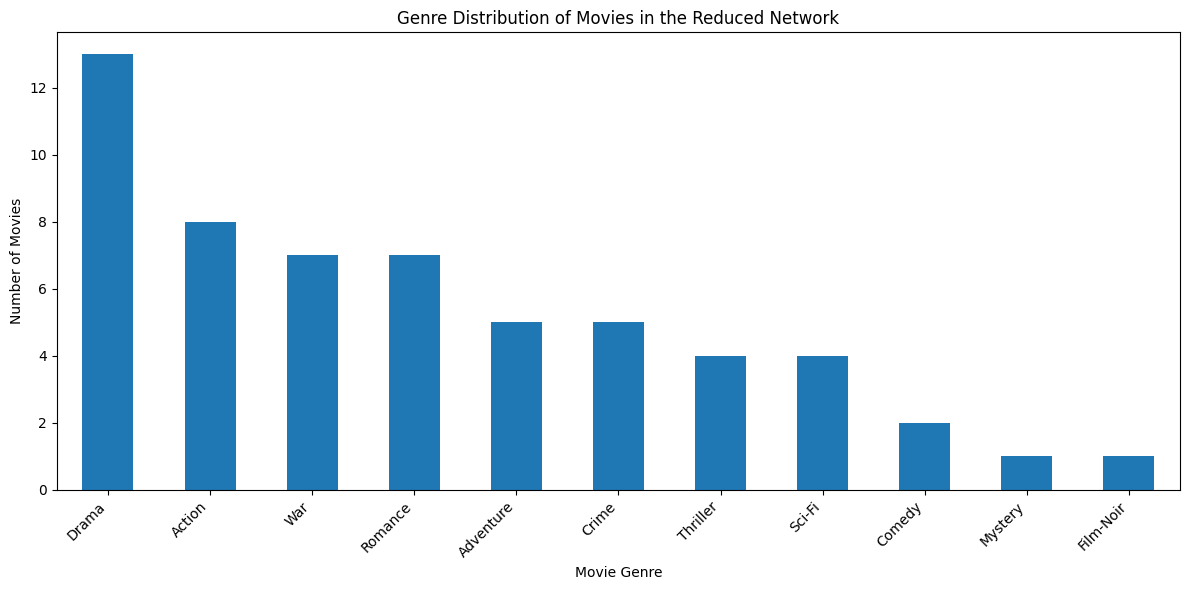

In [7]:
# Get movie IDs from the reduced network
selected_movie_ids = [
    int(node.split("_")[1])
    for node in top_movies
]

# Filter movie metadata to the selected movies
selected_movie_data = movies[
    movies["movie_id"].isin(selected_movie_ids)
].copy()

# Identify genre columns
genre_columns = [
    "unknown", "Action", "Adventure", "Animation",
    "Children", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

# Count how many selected movies belong to each genre
genre_counts = (
    selected_movie_data[genre_columns]
    .sum()
    .sort_values(ascending=False)
)

# Exclude genres with no movies
genre_counts = genre_counts[genre_counts > 0]

print("GENRE DISTRIBUTION AMONG THE 20 SELECTED MOVIES")
display(genre_counts.to_frame(name="Number_of_Movies"))

# Visualize the genre distribution
plt.figure(figsize=(12, 6))

genre_counts.plot(kind="bar")

plt.title("Genre Distribution of Movies in the Reduced Network")
plt.xlabel("Movie Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretation of Movie Genre Distribution

The genre analysis shows that Drama is the most common genre among the 20 movies in the reduced network, appearing in 13 movies (65%). Action is the second most common genre with 8 movies (40%), followed by War and Romance with 7 movies each (35%).

Adventure and Crime are also represented, with 5 movies each, while genres such as Comedy, Mystery, and Film-Noir appear less frequently.

These results suggest that the most frequently given 5-star ratings in this selected group are associated with movies that often contain dramatic, action-oriented, or historical themes.

It is important to note that movies can belong to multiple genres, so the total number of genre classifications exceeds the number of movies in the network.

The findings provide insight into the movie group by showing which genres are most common among the highly rated films. However, because the movies were selected based on their number of 5-star ratings, the results do not necessarily represent the preferences of all MovieLens users.

### Analyzing User Activity in the Reduced Network

After examining the movie genres, the next step is to analyze the user group.

I will calculate the number of connections for each of the 20 selected users. Since each connection represents a 5-star rating, this will show how many of the selected movies each user rated highly.

This analysis can help identify users who share positive preferences across many of the same movies, as well as users whose preferences overlap less with the selected movie group.

It is important to distinguish activity in the reduced network from overall user activity. A user with fewer connections in this network may still have rated many other movies outside the selected group.

USER ACTIVITY IN THE REDUCED NETWORK


,User,Five_Star_Connections
0,user_416,19
3,user_592,18
8,user_59,16
15,user_474,16
19,user_457,15
4,user_747,14
11,user_472,14
13,user_151,13
1,user_7,12
12,user_532,12



USER ACTIVITY SUMMARY


count    20.000000
mean     11.700000
std       4.231461
min       4.000000
25%      10.000000
50%      12.000000
75%      14.250000
max      19.000000
Name: Five_Star_Connections, dtype: float64

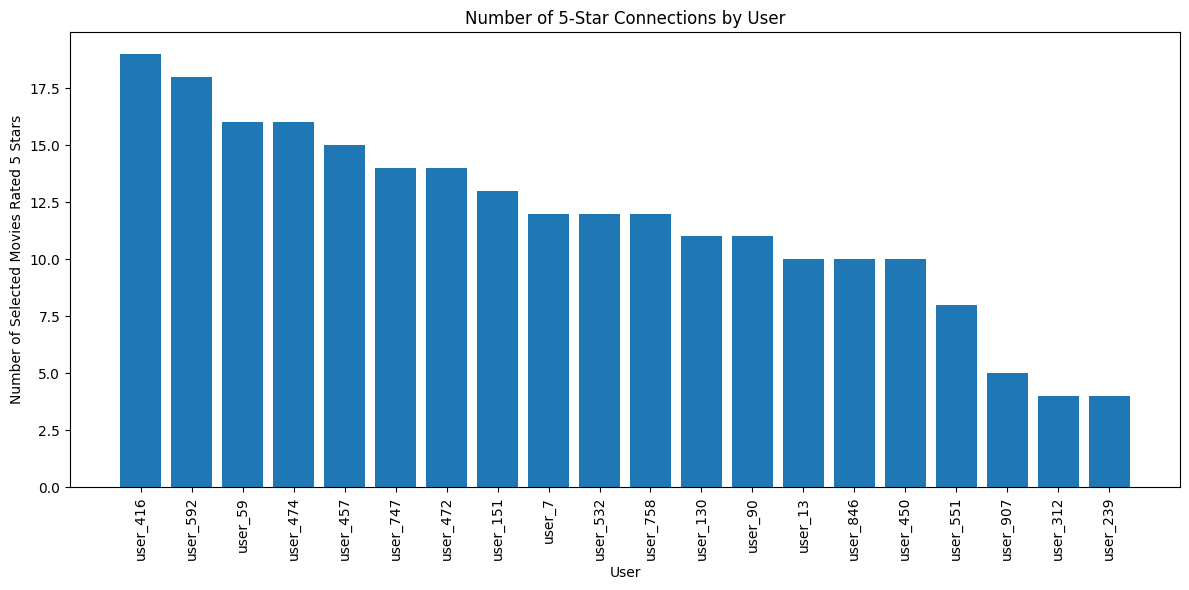

In [8]:
# Calculate the number of connections for each selected user
user_activity = pd.DataFrame({
    "User": top_users,
    "Five_Star_Connections": [
        G_small.degree(user) for user in top_users
    ]
})

# Sort users by number of connections
user_activity = user_activity.sort_values(
    by="Five_Star_Connections",
    ascending=False
)

print("USER ACTIVITY IN THE REDUCED NETWORK")
display(user_activity)

print("\nUSER ACTIVITY SUMMARY")
display(user_activity["Five_Star_Connections"].describe())

# Visualize user activity
plt.figure(figsize=(12, 6))

plt.bar(
    user_activity["User"],
    user_activity["Five_Star_Connections"]
)

plt.title("Number of 5-Star Connections by User")
plt.xlabel("User")
plt.ylabel("Number of Selected Movies Rated 5 Stars")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Interpretation of User Activity

The user activity analysis shows differences in the number of 5-star connections among the 20 selected users.

On average, each user gave 5-star ratings to 11.7 of the 20 selected movies. The median was 12 connections, suggesting that a typical user in this reduced network rated more than half of the selected movies highly.

User_416 had the highest number of connections, rating 19 of the 20 selected movies 5 stars. User_592 followed with 18 connections, while user_59 and user_474 each had 16 connections.

At the other end, user_312 and user_239 had only 4 connections each. This indicates that even among users selected for their high overall number of 5-star ratings, there are differences in how much their preferences overlap with the most frequently highly rated movies.

Overall, the findings suggest that some users share strong positive preferences for many of the same popular movies, while others have more distinct preferences.

However, fewer connections in the reduced network do not necessarily indicate lower overall activity, since users may have rated many other movies outside the selected group.

## 8. Conclusion

This project examined the MovieLens 100K dataset as a bipartite network consisting of two distinct groups: users and movies. The original network contained 943 users, 1,682 movies, and 100,000 connections representing movie ratings.

To reduce the network, I first applied an island-style rating threshold, retaining only connections representing 5-star ratings. This reduced the network to 21,201 edges. Because the network remained relatively large, I then selected the 20 most connected users and 20 most connected movies, producing a smaller network with 40 nodes and 234 edges.

The reduced network remained bipartite and consisted of a single connected component. This indicates that the selected users and movies were linked through shared positive movie preferences.

The analysis of the movie group showed that Drama was the most common genre, followed by Action, War, and Romance. This suggests that the selected highly rated movies frequently contain dramatic and action-oriented themes.

The user analysis showed that users had an average of 11.7 connections within the reduced network. Some users rated nearly all 20 selected movies 5 stars, while others had fewer connections. This suggests variation in how closely individual preferences align with the most frequently highly rated movies.

One limitation is that selecting highly connected users and movies favors popular films and active users. Additionally, filtering for 5-star ratings excludes lower ratings and does not capture the full range of movie preferences. The method is an island-inspired threshold reduction followed by degree-based filtering, rather than a strict implementation of the island algorithm.

Overall, this project demonstrates how bipartite network analysis can reveal relationships between two distinct groups and how network reduction can make a large dataset easier to examine and visualize.